<a href="https://colab.research.google.com/github/Prajwaln08/SQLSmith/blob/main/02_Spider_Error_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>


# SQLSmith — Notebook 02: Spider Error Analysis

**Milestone:** A — Baseline Evaluation  
**Model:** Qwen2.5-Coder-1.5B-Instruct  
**Dataset:** Spider 1.0 Development Set  
**Input:** Saved 50-question evaluation from Notebook 01

## Objectives
1. Load saved baseline predictions.
2. Validate result completeness and integrity.
3. Separate execution errors from SQL-result mismatches.
4. Create a structured error taxonomy.
5. Prepare manually reviewable semantic failures.
6. Save evaluation artifacts for Notebook 03.

**Important:** Accuracy reported here is provisional result-match accuracy, not official Spider test-suite accuracy.


## 1. Library Installation

In [24]:
# Install necessary parsing, manipulation, and plotting libraries
%pip install -q pandas numpy matplotlib sqlglot

## 2. Environment Setup and Google Drive Connection

In [25]:
# Mount Google Drive and set up the working directories for the analysis
from google.colab import drive
from pathlib import Path

# Mount drive
drive.mount("/content/drive")

# Define paths
PROJECT_DIR = Path(
    "/content/drive/MyDrive/Prajwal/Projects/SQLSmith"
)
RESULTS_DIR = PROJECT_DIR / "results"
ANALYSIS_DIR = RESULTS_DIR

# Ensure output directories exist
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

INPUT_FILE = RESULTS_DIR / "spider_1_5b_baseline_50.csv"

# Ensure the baseline results file is present
assert INPUT_FILE.exists(), (
    f"Baseline file not found: {INPUT_FILE}"
)

print("Project:", PROJECT_DIR)
print("Results:", RESULTS_DIR)
print("Input file found:", INPUT_FILE.name)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Project: /content/drive/MyDrive/Prajwal/Projects/SQLSmith
Results: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results
Input file found: spider_1_5b_baseline_50.csv


## 3. Data Load and Baseline Integrity Checks

In [26]:
# Load baseline predictions and validate columns, indices, and correctness formats
import pandas as pd
import numpy as np

# Load the evaluation CSV into a Pandas DataFrame
df = pd.read_csv(INPUT_FILE)

# Define columns required for evaluation
required_columns = [
    "index",
    "db_id",
    "question",
    "gold_sql",
    "predicted_sql",
    "correct",
    "latency_seconds",
    "error"
]

# Ensure all necessary columns exist
missing = [
    col for col in required_columns
    if col not in df.columns
]
assert not missing, f"Missing columns: {missing}"

# Normalize and parse Boolean values safely
def parse_correct(value):
    if isinstance(value, (bool, np.bool_)):
        return bool(value)
    text = str(value).strip().lower()
    if text in ("true", "1"):
        return True
    if text in ("false", "0"):
        return False
    raise ValueError(f"Unexpected correctness value: {value}")

df["correct"] = df["correct"].apply(parse_correct)

# Cast latency to numeric types, handling empty metrics as NaN
df["latency_seconds"] = pd.to_numeric(
    df["latency_seconds"],
    errors="coerce"
)

# Validate unique index constraints and data consistency
assert not df["index"].duplicated().any(), "Duplicate question indices found"
assert not df["db_id"].isna().any(), "Missing database IDs found"

# Display data-load summary metrics
print("Total questions:", len(df))
print("Correct:", int(df["correct"].sum()))
print("Incorrect:", int((~df["correct"]).sum()))
print("Unique databases:", df["db_id"].nunique())

display(df.head())

Total questions: 50
Correct: 24
Incorrect: 26
Unique databases: 2


,index,db_id,question,gold_sql,predicted_sql,correct,latency_seconds,error
0,1,concert_singer,How many singers do we have?,SELECT count(*) FROM singer,SELECT count(*) FROM singer,True,1.379505,NaN
1,2,concert_singer,What is the total number of singers?,SELECT count(*) FROM singer,SELECT count(*) FROM singer,True,1.143007,NaN
2,3,concert_singer,"Show name, country, age for all singers ordere...","SELECT name , country , age FROM singer ORDE...","SELECT Name, Country, Age FROM singer ORDER BY...",True,2.068415,NaN
3,4,concert_singer,"What are the names, countries, and ages for ev...","SELECT name , country , age FROM singer ORDE...","SELECT name, country, age FROM singer ORDER BY...",True,2.294654,NaN
4,5,concert_singer,"What is the average, minimum, and maximum age ...","SELECT avg(age) , min(age) , max(age) FROM s...","SELECT AVG(Age) , MIN(Age) , MAX(Age) FROM s...",True,5.696822,NaN


## 4. Performance Metrics and Baseline Latency Aggregation

In [27]:
# Calculate baseline metrics and summarize performance
accuracy = df["correct"].mean() * 100

# Compute overall latency metrics
mean_latency = df["latency_seconds"].mean()
median_latency = df["latency_seconds"].median()
p95_latency = df["latency_seconds"].quantile(0.95)

# Wrap aggregated metrics in a summary DataFrame
summary_df = pd.DataFrame([{
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "dataset": "Spider 1.0 dev (first 50)",
    "total_questions": len(df),
    "correct": int(df["correct"].sum()),
    "incorrect": int((~df["correct"]).sum()),
    "provisional_accuracy_pct": round(accuracy, 2),
    "mean_latency_sec": round(mean_latency, 3),
    "median_latency_sec": round(median_latency, 3),
    "p95_latency_sec": round(p95_latency, 3)
}])

display(summary_df)

,model,dataset,total_questions,correct,incorrect,provisional_accuracy_pct,mean_latency_sec,median_latency_sec,p95_latency_sec
0,Qwen2.5-Coder-1.5B-Instruct,Spider 1.0 dev (first 50),50,24,26,48.0,3.629,3.045,9.444


## 5. Filtering and Isolating Execution/Evaluation Failures

In [28]:
# Filter out failed predictions to prepare for taxonomy isolation
failures = df.loc[~df["correct"]].copy()

# Handle and clean null values in core text columns
failures["predicted_sql"] = failures["predicted_sql"].fillna("")
failures["gold_sql"] = failures["gold_sql"].fillna("")
failures["error"] = failures["error"].fillna("")

print("Total failed questions:", len(failures))

# Display structured failure tracking
display(
    failures[
        [
            "index",
            "db_id",
            "question",
            "gold_sql",
            "predicted_sql",
            "error"
        ]
    ]
)

Total failed questions: 26


,index,db_id,question,gold_sql,predicted_sql,error
6,7,concert_singer,Show the name and the release year of the song...,"SELECT song_name , song_release_year FROM sin...","SELECT T2.song_name, T2.song_release_year FROM...",no such column: T2.song_name
7,8,concert_singer,What are the names and release years for all t...,"SELECT song_name , song_release_year FROM sin...","SELECT T2.song_name, T2.song_release_year FROM...",no such column: T2.song_name
8,9,concert_singer,What are all distinct countries where singers ...,SELECT DISTINCT country FROM singer WHERE age ...,SELECT DISTINCT T1.Country FROM singer AS T1 I...,
10,11,concert_singer,Show all countries and the number of singers i...,"SELECT country , count(*) FROM singer GROUP B...","SELECT T1.Country, COUNT(T2.Singer_ID) FROM si...",
11,12,concert_singer,How many singers are from each country?,"SELECT country , count(*) FROM singer GROUP B...","SELECT COUNT(*) , Country FROM singer GROUP B...",
12,13,concert_singer,List all song names by singers above the avera...,SELECT song_name FROM singer WHERE age > (SE...,SELECT T2.song_name FROM singer AS T1 JOIN sin...,no such column: T2.song_name
13,14,concert_singer,What are all the song names by singers who are...,SELECT song_name FROM singer WHERE age > (SE...,SELECT T2.song_name FROM singer AS T1 INNER JO...,no such column: T2.song_name
16,17,concert_singer,What is the maximum capacity and the average o...,"select max(capacity), average from stadium","SELECT max(capacity), avg(capacity) FROM stadium",
18,19,concert_singer,What is the name and capacity for the stadium ...,"SELECT name , capacity FROM stadium ORDER BY ...","SELECT T1.Name, T1.Capacity FROM stadium AS T1...",no such column: T3.Age
19,20,concert_singer,What is the name and capacity for the stadium ...,"SELECT name , capacity FROM stadium ORDER BY ...","SELECT T1.Name, T1.Capacity FROM stadium AS T1...",no such column: Average_number


 ## 6. Categorizing Failure Modes with an Error Taxonomy Rule-Set

In [29]:
# Classify failures based on error messages and missing query logic
def classify_execution_error(row):
    error = str(row["error"]).lower().strip()
    predicted_sql = str(row["predicted_sql"]).strip()

    if not predicted_sql:
        return "Empty generation"
    if not error:
        return "Semantic mismatch - review required"
    if "no such column" in error:
        return "Invalid column"
    if "no such table" in error:
        return "Invalid table"
    if (
        "syntax error" in error
        or "incomplete input" in error
        or "unrecognized token" in error
    ):
        return "SQL syntax error"
    if "interrupted" in error or "timeout" in error:
        return "Execution timeout"
    if "expected a single select" in error:
        return "Query validation rejection"
    if "unsupported" in error:
        return "Unsupported SQL construct"
    if "ambiguous column" in error:
        return "Ambiguous column"

    return "Other execution/evaluation error"

# Apply the error category mapper across row objects
failures["initial_error_category"] = failures.apply(
    classify_execution_error,
    axis=1
)

# Aggregate and count categorical failures
category_counts = (
    failures["initial_error_category"]
    .value_counts()
    .reset_index()
)
category_counts.columns = [
    "error_category",
    "count"
]

display(category_counts)

,error_category,count
0,Invalid column,12
1,Semantic mismatch - review required,9
2,Query validation rejection,5


## 7. Distribution Analysis of Categorized Failure Types

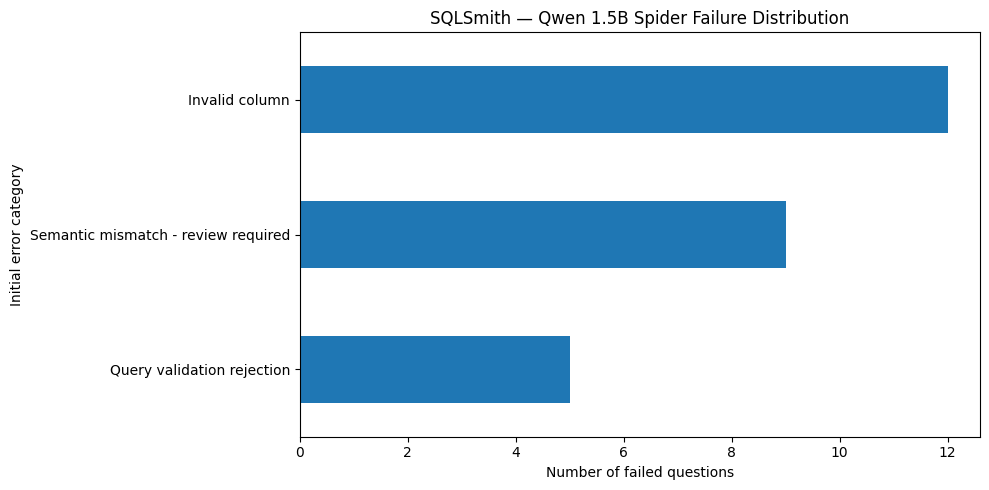

In [30]:
# Visualize error category frequency distributions
import matplotlib.pyplot as plt

# Sort categories for horizontal bar visualization
counts = failures[
    "initial_error_category"
].value_counts().sort_values()

plt.figure(figsize=(10, 5))
counts.plot(kind="barh")

plt.xlabel("Number of failed questions")
plt.ylabel("Initial error category")
plt.title(
    "SQLSmith — Qwen 1.5B Spider Failure Distribution"
)

plt.tight_layout()
plt.show()

## 8. Extracting Semantic Failures for Manual Review and Evaluation

In [31]:
# Filter out valid executions with semantic mismatches for manual review templates
semantic = failures[
    failures["initial_error_category"]
    == "Semantic mismatch - review required"
].copy()

# Prepopulate layout values for user-guided categorization and comments
semantic["manual_error_category"] = ""
semantic["reviewer_notes"] = ""
semantic["review_status"] = "PENDING"
semantic["suggested_root_cause"] = ""

review_columns = [
    "index",
    "db_id",
    "question",
    "gold_sql",
    "predicted_sql",
    "initial_error_category",
    "manual_error_category",
    "suggested_root_cause",
    "reviewer_notes",
    "review_status"
]

review_file = (
    ANALYSIS_DIR /
    "spider_1_5b_error_review_template.csv"
)

# Export template to disk
semantic[review_columns].to_csv(
    review_file,
    index=False
)

print("Semantic review cases:", len(semantic))
print("Saved:", review_file)

display(semantic[review_columns].head(10))

Semantic review cases: 9
Saved: /content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_review_template.csv


,index,db_id,question,gold_sql,predicted_sql,initial_error_category,manual_error_category,suggested_root_cause,reviewer_notes,review_status
8,9,concert_singer,What are all distinct countries where singers ...,SELECT DISTINCT country FROM singer WHERE age ...,SELECT DISTINCT T1.Country FROM singer AS T1 I...,Semantic mismatch - review required,,,,PENDING
10,11,concert_singer,Show all countries and the number of singers i...,"SELECT country , count(*) FROM singer GROUP B...","SELECT T1.Country, COUNT(T2.Singer_ID) FROM si...",Semantic mismatch - review required,,,,PENDING
11,12,concert_singer,How many singers are from each country?,"SELECT country , count(*) FROM singer GROUP B...","SELECT COUNT(*) , Country FROM singer GROUP B...",Semantic mismatch - review required,,,,PENDING
16,17,concert_singer,What is the maximum capacity and the average o...,"select max(capacity), average from stadium","SELECT max(capacity), avg(capacity) FROM stadium",Semantic mismatch - review required,,,,PENDING
22,23,concert_singer,Show the stadium name and the number of concer...,"SELECT T2.name , count(*) FROM concert AS T1 ...","SELECT T1.Name, COUNT(T2.concert_ID) FROM stad...",Semantic mismatch - review required,,,,PENDING
28,29,concert_singer,Show the stadium names without any concert.,SELECT name FROM stadium WHERE stadium_id NOT ...,SELECT name FROM stadium WHERE stadium_id NOT ...,Semantic mismatch - review required,,,,PENDING
29,30,concert_singer,What are the names of the stadiums without any...,SELECT name FROM stadium WHERE stadium_id NOT ...,SELECT name FROM stadium WHERE stadium_id NOT ...,Semantic mismatch - review required,,,,PENDING
40,41,concert_singer,What is the name and country of origin of ever...,"SELECT name , country FROM singer WHERE song_...","SELECT T1.Name, T1.Country FROM singer AS T1 I...",Semantic mismatch - review required,,,,PENDING
47,48,pets_1,Find the weight of the youngest dog.,SELECT weight FROM pets ORDER BY pet_age LIMIT 1,SELECT T2.weight FROM Has_Pet AS T1 INNER JOIN...,Semantic mismatch - review required,,,,PENDING


## 9. Detailed Step-by-Step Inspectable Review Log

In [32]:
# Iterate over and output all tracked failures in an easily readable terminal format
for _, row in failures.iterrows():
    print("=" * 90)
    print("Question ID:", row["index"])
    print("Database:", row["db_id"])
    print("Question:", row["question"])

    print("\nGOLD SQL:")
    print(row["gold_sql"])

    print("\nPREDICTED SQL:")
    print(row["predicted_sql"])

    print("\nINITIAL CATEGORY:")
    print(row["initial_error_category"])

    if row["error"]:
        print("\nERROR:")
        print(row["error"])

    print()

Question ID: 7
Database: concert_singer
Question: Show the name and the release year of the song by the youngest singer.

GOLD SQL:
SELECT song_name ,  song_release_year FROM singer ORDER BY age LIMIT 1

PREDICTED SQL:
SELECT T2.song_name, T2.song_release_year FROM singer AS T1 INNER JOIN singer_in_concert AS T3 ON T1.singer_id = T3.singer_id INNER JOIN concert AS T4 ON T3.concert_id = T4.concert_id ORDER BY T1.age ASC LIMIT 1

INITIAL CATEGORY:
Invalid column

ERROR:
no such column: T2.song_name

Question ID: 8
Database: concert_singer
Question: What are the names and release years for all the songs of the youngest singer?

GOLD SQL:
SELECT song_name ,  song_release_year FROM singer ORDER BY age LIMIT 1

PREDICTED SQL:
SELECT T2.song_name, T2.song_release_year FROM singer AS T1 INNER JOIN singer_in_concert AS T3 ON T1.singer_id = T3.singer_id INNER JOIN concert AS T4 ON T3.concert_id = T4.concert_id ORDER BY T1.age ASC LIMIT 1

INITIAL CATEGORY:
Invalid column

ERROR:
no such column: 

## 10. Exporting Analysis Artifacts and Executing Health Verifications

In [33]:
# Export evaluation reports, logs, configurations and JSON metadata reports
from datetime import datetime, timezone
import json

# Export details of failures to CSV
error_file = (
    RESULTS_DIR /
    "spider_1_5b_error_analysis.csv"
)
failures.to_csv(error_file, index=False)

# Export failure distribution summary
summary_file = (
    RESULTS_DIR /
    "spider_1_5b_error_summary.csv"
)
category_counts.to_csv(summary_file, index=False)

# Construct summary JSON report mapping evaluation characteristics
report = {
    "experiment": "spider_1_5b_error_analysis",
    "model": "Qwen2.5-Coder-1.5B-Instruct",
    "dataset": "Spider 1.0 development set",
    "sample_size": int(len(df)),
    "correct": int(df["correct"].sum()),
    "incorrect": int((~df["correct"]).sum()),
    "provisional_accuracy_pct": round(accuracy, 2),
    "mean_latency_seconds": round(float(mean_latency), 4),
    "median_latency_seconds": round(float(median_latency), 4),
    "p95_latency_seconds": round(float(p95_latency), 4),
    "semantic_cases_pending_review": int(len(semantic)),
    "initial_error_categories": {
        str(key): int(value)
        for key, value in failures[
            "initial_error_category"
        ].value_counts().items()
    },
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "evaluation_status": "provisional",
    "official_spider_scoring": False
}

json_file = (
    RESULTS_DIR /
    "spider_1_5b_analysis_summary.json"
)

with open(json_file, "w") as f:
    json.dump(report, f, indent=2)

print("Saved files:")
print(error_file)
print(summary_file)
print(review_file)
print(json_file)

Saved files:
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_analysis.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_summary.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_error_review_template.csv
/content/drive/MyDrive/Prajwal/Projects/SQLSmith/results/spider_1_5b_analysis_summary.json


In [34]:
# Execute final schema validations on output analysis artifacts
required_outputs = [
    "spider_1_5b_error_analysis.csv",
    "spider_1_5b_error_review_template.csv",
    "spider_1_5b_error_summary.csv",
    "spider_1_5b_analysis_summary.json"
]

# Assert absolute paths of exports exist correctly on drive mount
for filename in required_outputs:
    filepath = RESULTS_DIR / filename
    assert filepath.exists(), (
        f"Missing output: {filename}"
    )
    print("PASS:", filename)

# Double-check total metrics math match sum logic rules
assert len(failures) == int(
    (~df["correct"]).sum()
)
assert category_counts["count"].sum() == len(failures)

print("\nNotebook 02 initial analysis completed.")
print("Manual semantic review remains pending.")

PASS: spider_1_5b_error_analysis.csv
PASS: spider_1_5b_error_review_template.csv
PASS: spider_1_5b_error_summary.csv
PASS: spider_1_5b_analysis_summary.json

Notebook 02 initial analysis completed.
Manual semantic review remains pending.
